# 05 · District scores and the default plan

For each district we combine four factors, each rescaled 0–1 across the 30 districts:

| Factor | Measure | Default weight |
|---|---|---|
| **Water gain** | Extra RWF per irrigated hectare per season = Σ crop share × rain-fed yield × water bonus × price | 40% |
| **Adoption gap** | 1 − share of small-farm area already irrigated | 20% |
| **Dryness** | Less June–August rain scores higher | 20% |
| **Poverty** | EICV7 poverty rate | 20% |

Crop shares, rain-fed sole-crop yields, irrigated share and farm-gate prices come from SAS 2023–2025 (the most
recent three years). This notebook writes the two files the API serves: `data/processed/crops.json` and
`districts.json`. They hold aggregates only.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from kuhira import build, plan, style
from kuhira import district_stats as ds
from kuhira.paths import INTERIM
from kuhira.rainfall import dry_season_mm

style.use()
plots = pd.read_parquet(INTERIM / "plots.parquet")
recent = ds.recent_small(plots)
bonus = pd.read_csv(INTERIM / "water_bonus.csv")
crops = build.crops_table(bonus, ds.crop_prices(recent), ds.national_rainfed_yields(recent))
districts = build.districts_table(recent, dry_season_mm(pd.read_parquet(INTERIM / "rain_monthly.parquet")),
                                  build.load_poverty())
build.write(crops, districts)
pd.DataFrame(crops)[["crop", "bonus_pct", "p_value", "price_rwf_per_kg", "yield_kg_per_ha"]]

,crop,bonus_pct,p_value,price_rwf_per_kg,yield_kg_per_ha
0,Maize,14.6,0.0000,340.0,1424.010017
1,Beans,-10.3,0.0009,650.0,644.916631
2,Irish potato,9.7,0.0994,350.0,7753.945231
3,Sweet potato,15.2,0.0000,200.0,7353.017202
4,Vegetables,20.3,0.0000,250.0,6702.852584
5,Sorghum,-4.0,0.6112,500.0,1122.050525
6,Cassava,-3.5,0.5842,250.0,8410.742922
7,Paddy rice,9.0,0.0655,500.0,2513.639646
8,Soybean,-1.0,0.8939,700.0,304.390570
9,Wheat,NaN,NaN,700.0,1228.226566


## Ranking with the default weights

In [2]:
plan.load_crops.cache_clear(); plan.load_districts.cache_clear()
C, D = plan.load_crops(), plan.load_districts()
ranked = pd.DataFrame(plan.score(D, C, plan.Weights()))
ranked[["rank", "district", "province", "score", "gain_rwf_per_ha", "irrigated_share", "dry_season_mm",
        "poverty_rate_pct"]].head(10)

,rank,district,province,score,gain_rwf_per_ha,irrigated_share,dry_season_mm,poverty_rate_pct
0,1,Nyamagabe,South,84.8,49014,0.0121,75.7,51.39
1,2,Nyaruguru,South,78.9,50185,0.0216,66.1,39.70
2,3,Rubavu,West,73.3,47974,0.0019,119.0,38.81
3,4,Gakenke,North,63.9,40392,0.0110,78.4,24.47
4,5,Karongi,West,62.4,36996,0.0149,91.8,38.19
5,6,Nyagatare,East,61.3,31820,0.0183,60.8,36.37
6,7,Ngororero,West,59.2,34012,0.0096,85.9,30.24
7,8,Burera,North,57.8,35708,0.0037,94.0,21.79
8,9,Rutsiro,West,56.1,28555,0.0034,109.5,40.78
9,10,Nyamasheke,West,55.7,29434,0.0149,96.9,42.67


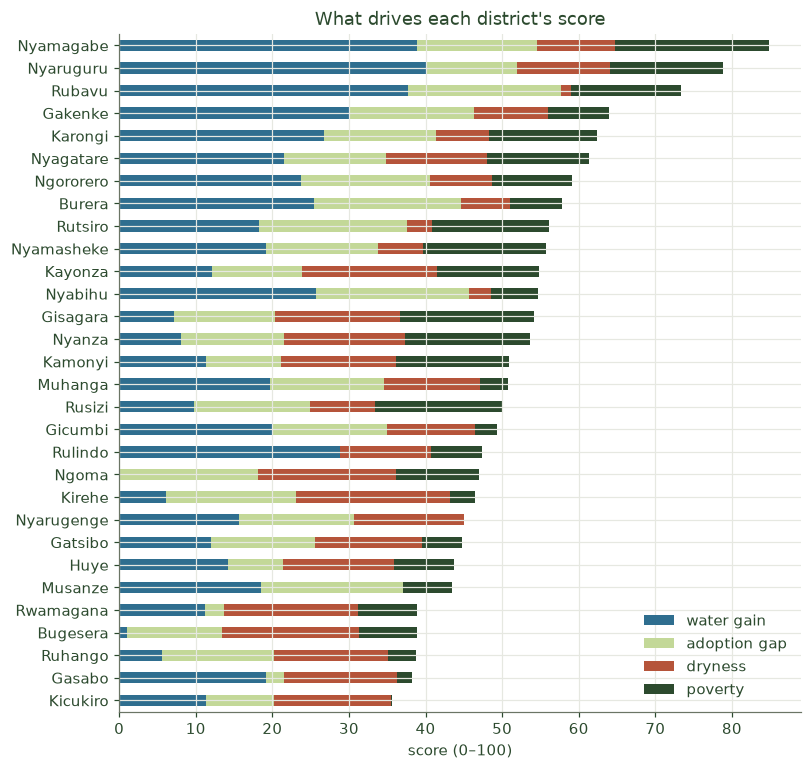

In [3]:
f = pd.DataFrame(ranked.factors.tolist(), index=ranked.district)
ax = (f * pd.Series(plan.Weights().model_dump()) * 100).plot(
    kind="barh", stacked=True, figsize=(8, 8), color=[style.WATER, style.PRIMARY, style.CLAY, style.FOREST])
ax.invert_yaxis()
ax.set(xlabel="score (0–100)", ylabel="", title="What drives each district's score")
ax.legend(["water gain", "adoption gap", "dryness", "poverty"], frameon=False, loc="lower right");

## What the bean penalty costs each district
Across districts, beans' share of the crop area barely predicts the water gain (other crops matter more). The
direct test: recompute each district's gain as if irrigated beans broke even, and compare.

In [4]:
no_penalty = C | {"Beans": C["Beans"].model_copy(update={"bonus_pct": 0.0})}
beans = pd.DataFrame([{
    "district": d.district,
    "bean_share": next((c.share for c in d.crops if c.crop == "Beans"), 0),
    "gain_rwf_per_ha": plan.gain_per_ha(d, C),
    "gain_if_beans_broke_even": plan.gain_per_ha(d, no_penalty),
} for d in D.values()])
beans["penalty_pct"] = 100 * (1 - beans.gain_rwf_per_ha / beans.gain_if_beans_broke_even)
beans.sort_values("penalty_pct", ascending=False).head(8).round(2)

,district,bean_share,gain_rwf_per_ha,gain_if_beans_broke_even,penalty_pct
15,Ngoma,0.23,10368.57,20646.15,49.78
14,Musanze,0.30,28810.94,49198.34,41.44
12,Kirehe,0.27,16456.65,25842.97,36.32
0,Bugesera,0.23,11426.30,17833.82,35.93
1,Burera,0.28,35708.41,55199.38,35.31
27,Rusizi,0.25,20060.55,30237.75,33.66
5,Gicumbi,0.28,30315.69,45465.50,33.32
6,Gisagara,0.27,17543.37,25568.69,31.39


Counting the bean penalty **halves Ngoma's water gain** and cuts Musanze's by about 40%. A planner using a
blanket "irrigation raises yields" assumption would overrate these districts; Kuhira does not.

## Is the ranking fragile?
Re-rank under four very different weightings. Districts that stay near the top whatever you believe are the
safe first picks.

In [5]:
schemes = {"default": plan.Weights(), "gain only": plan.Weights(gain=1, gap=0, dryness=0, poverty=0),
           "equal": plan.Weights(gain=.25, gap=.25, dryness=.25, poverty=.25),
           "pro-poor": plan.Weights(gain=.2, gap=.2, dryness=.2, poverty=.4),
           "drought": plan.Weights(gain=.3, gap=.1, dryness=.5, poverty=.1)}
ranks = pd.DataFrame({k: {r["district"]: r["rank"] for r in plan.score(D, C, w)} for k, w in schemes.items()})
ranks.assign(worst=ranks.max(axis=1)).sort_values("default").head(10)

,default,gain only,equal,pro-poor,drought,worst
Nyamagabe,1,2,1,1,2,2
Nyaruguru,2,1,2,2,1,2
Rubavu,3,3,3,3,24,24
Gakenke,4,4,8,15,9,15
Karongi,5,6,7,7,20,20
Nyagatare,6,10,4,6,5,10
Ngororero,7,9,10,14,21,21
Burera,8,8,16,16,25,25
Rutsiro,9,16,12,9,29,29
Nyamasheke,10,14,13,8,27,27


## The default plan: the remaining 13,368 ha
PSTA5 targets 41,031 ha of small-scale irrigation by 2028/29; 27,663 ha were in place by FY2024/25. Hectares are
split in proportion to score × small-farm cropland. Kit cost: ~RWF 1.35 M/ha (RAB 2019, $1,500/ha), 50% subsidy.

In [6]:
alloc = plan.allocate(plan.score(D, C, plan.Weights()), plan.REMAINING_HA, plan.COST_PER_HA_RWF, plan.SUBSIDY_REGULAR)
pd.DataFrame(alloc["districts"]).head(10)

,district,rank,score,hectares,public_cost_rwf,farmer_cost_rwf,extra_value_rwf_per_year
0,Nyamagabe,1,84.8,683,461134790,461134790,66969068
1,Nyaruguru,2,78.9,480,323811922,323811922,48149633
2,Rubavu,3,73.3,369,249321283,249321283,35439820
3,Gakenke,4,63.9,598,403733740,403733740,48318854
4,Karongi,5,62.4,497,335515370,335515370,36778449
5,Nyagatare,6,61.3,1112,750413676,750413676,70750113
6,Ngororero,7,59.2,492,332137165,332137165,33471553
7,Burera,8,57.8,461,310962128,310962128,32900254
8,Rutsiro,9,56.1,339,229087838,229087838,19382528
9,Nyamasheke,10,55.7,407,274823226,274823226,23967842


In [7]:
t = alloc["totals"]
pd.Series({"hectares": f"{t['hectares']:,}", "public cost (RWF bn)": round(t["public_cost_rwf"] / 1e9, 1),
           "farmers' share (RWF bn)": round(t["farmer_cost_rwf"] / 1e9, 1),
           "extra harvest value per year (RWF bn)": round(t["extra_value_rwf_per_year"] / 1e9, 1)})

hectares                                 13,368
public cost (RWF bn)                        9.0
farmers' share (RWF bn)                     9.0
extra harvest value per year (RWF bn)       0.8
dtype: object

**Reading the totals honestly.** At about RWF 0.8 bn a year of extra harvest against RWF 18 bn of kit, *yield gains
alone, on today's crops, in Seasons A and B* repay slowly. That figure is a floor: it leaves out the Season C
harvest that irrigation makes possible and any switch to vegetables (+20%, ~RWF 340k per irrigated ha per season
at survey yields and prices). The ranking does not depend on this level, only on how districts compare.